In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.semi_supervised import LabelSpreading
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [2]:
df = pd.read_csv('/content/Telco-Customer-Churn.csv')

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Column Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nTarget Distribution:")
print(df['Churn'].value_counts())

Column Names:
Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   I

In [4]:
df = df.drop('customerID', axis=1)

In [5]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'], errors='coerce'
)

df = df.dropna()

print("Missing Values:", df.isnull().sum().sum())
print("Updated Shape:", df.shape)

Missing Values: 0
Updated Shape: (7032, 20)


In [6]:
X = df.drop('Churn', axis=1)
y = df['Churn'].map({'No': 0, 'Yes': 1})

X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (7032, 30)
Target Shape: (7032,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (5625, 30)
Testing Data: (1407, 30)


In [8]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [9]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)

print("KNN Model Trained Successfully!")

KNN Model Trained Successfully!


In [10]:
print("KNN Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_knn))

print("Precision:", precision_score(y_test, y_pred_knn, zero_division=0))

print("Recall:", recall_score(y_test, y_pred_knn, zero_division=0))

print("F1 Score:", f1_score(y_test, y_pred_knn, zero_division=0))

KNN Performance
Accuracy: 0.7533759772565742
Precision: 0.5361930294906166
Recall: 0.5347593582887701
F1 Score: 0.535475234270415


In [11]:
y_semi = y_train.to_numpy().copy()

np.random.seed(42)

unlabeled_indices = np.random.choice(
    len(y_semi),
    size=int(0.5 * len(y_semi)),
    replace=False
)

y_semi[unlabeled_indices] = -1

print("Original Training Samples:", len(y_train))
print("Unlabelled Samples:", np.sum(y_semi == -1))
print("Labelled Samples:", np.sum(y_semi != -1))

Original Training Samples: 5625
Unlabelled Samples: 2812
Labelled Samples: 2813


In [12]:
semi_model = LabelSpreading(
    kernel='knn',
    n_neighbors=7,
    max_iter=100
)

semi_model.fit(X_train_scaled, y_semi)

y_pred_semi = semi_model.predict(X_test_scaled)

print("Label Spreading Model Trained Successfully!")

Label Spreading Model Trained Successfully!


In [13]:
print("Label Spreading Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_semi))

print("Precision:", precision_score(y_test, y_pred_semi, zero_division=0))

print("Recall:", recall_score(y_test, y_pred_semi, zero_division=0))

print("F1 Score:", f1_score(y_test, y_pred_semi, zero_division=0))

Label Spreading Performance
Accuracy: 0.7448471926083866
Precision: 0.519280205655527
Recall: 0.5401069518716578
F1 Score: 0.5294888597640891


In [14]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [15]:
print("Random Forest Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("Precision:", precision_score(y_test, y_pred_rf, zero_division=0))

print("Recall:", recall_score(y_test, y_pred_rf, zero_division=0))

print("F1 Score:", f1_score(y_test, y_pred_rf, zero_division=0))

Random Forest Performance
Accuracy: 0.7896233120113717
Precision: 0.6258064516129033
Recall: 0.5187165775401069
F1 Score: 0.5672514619883041


In [16]:
results = pd.DataFrame({
    'Model': [
        'KNN',
        'Label Spreading',
        'Random Forest'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_semi),
        accuracy_score(y_test, y_pred_rf)
    ],

    'Precision': [
        precision_score(y_test, y_pred_knn, zero_division=0),
        precision_score(y_test, y_pred_semi, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0)
    ],

    'Recall': [
        recall_score(y_test, y_pred_knn, zero_division=0),
        recall_score(y_test, y_pred_semi, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0)
    ],

    'F1 Score': [
        f1_score(y_test, y_pred_knn, zero_division=0),
        f1_score(y_test, y_pred_semi, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.753376,0.536193,0.534759,0.535475
1,Label Spreading,0.744847,0.519280,0.540107,0.529489
2,Random Forest,0.789623,0.625806,0.518717,0.567251


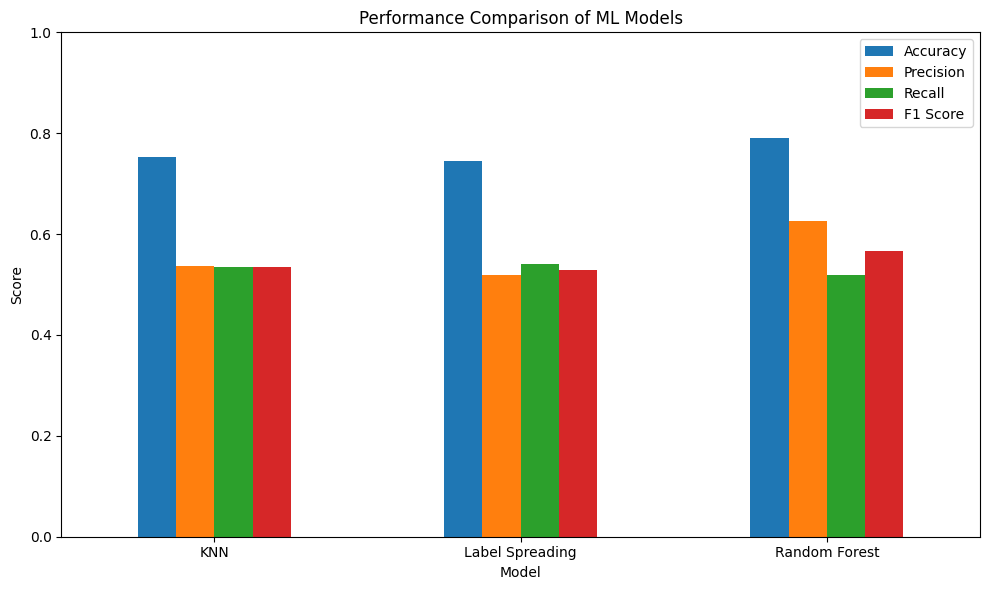

In [17]:
results.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Performance Comparison of ML Models')
plt.ylabel('Score')
plt.xlabel('Model')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

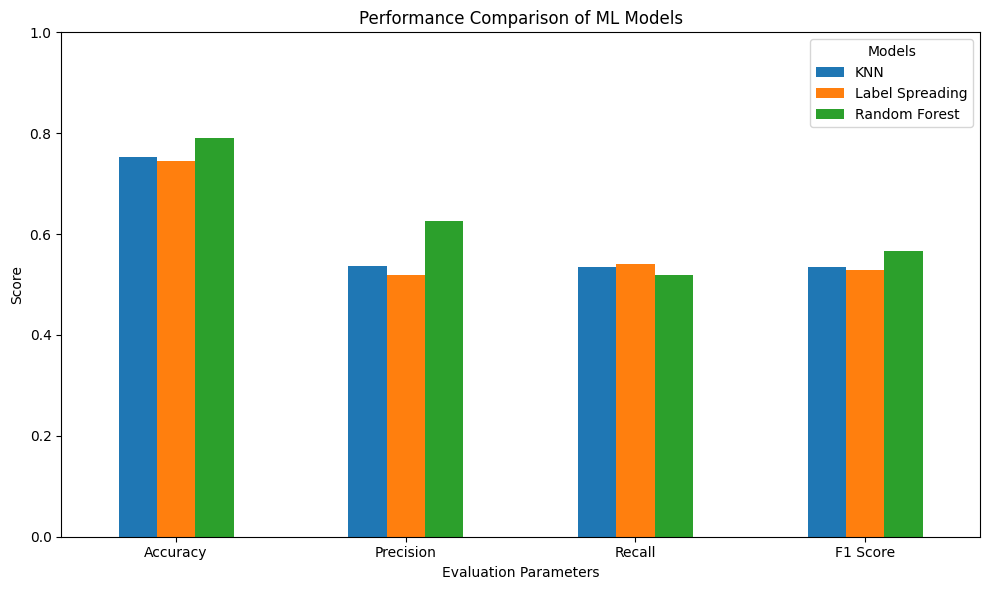

In [19]:
results.set_index('Model').T.plot(kind='bar', figsize=(10, 6))

plt.title('Performance Comparison of ML Models')
plt.xlabel('Evaluation Parameters')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Models')
plt.tight_layout()
plt.show()